# 05 — Audit Diagnostik Reproducible: Overfitting, MIL-Attention, FiLM, Konsep, & Bag-Size Shortcut

Notebook ini **hanya membaca hasil tersimpan** di `Proposed Model 3/runs/` (pure CPU, tanpa GPU & tanpa training ulang) untuk mengaudit dan memvisualisasikan:
1. **Bagian 1:** Kurva overfitting 5-fold (`stage7_only` vs `stage7_8` vs `stage8_only`) beserta dekomposisi *loss* per komponen (`diag`, `comp`, `hier_nll`, `concept`, `aux_img`).
2. **Bagian 2:** Apakah MIL-Attention benar-benar selektif (*entropy* & *spread*), apakah modulasi FiLM aktif, dan performa 8 konsep sonografis.
3. **Bagian 3:** Bukti empiris ***bag-size shortcut*** ($K_i$) pada `mv_lstm` vs `cross_attn` (Image-Only maupun Multimodal), termasuk evaluasi terstratifikasi pada jumlah foto tetap ($K=1$, $K=2$, $K\ge 3$).
4. **Bagian 4:** Menyimpan seluruh tabel CSV, grafik PNG resolusi tinggi, dan laporan teks terstruktur ke `runs/05_diagnostic_audits/` untuk kebutuhan penulisan laporan/tesis.


In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, f1_score

# Resolusi path otomatis dari root proyek atau folder Proposed Model 3
candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT_DIR = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import load_cohort, images_by_patient, is_appendix_label

RUNS_DIR = PM3_DIR / "runs"
OUT_DIR = RUNS_DIR / "05_diagnostic_audits"
OUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_BACKBONE = "stage7_only"
BACKBONES = ("stage7_only", "stage7_8", "stage8_only")

cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
manifest["image_id"] = manifest["image_id"].astype(str)
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
bags_all = images_by_patient(manifest, bag_mode="all")

def resolve_b2_dir(modality: str, task_mode: str, agg: str) -> Path:
    if modality == "multimodal" and task_mode == "hierarchical" and agg == "cross_attn":
        canon = RUNS_DIR / f"02_backbone_{BEST_BACKBONE}"
        if (canon / "oof_metrics_calibrated.json").exists():
            return canon
    return RUNS_DIR / f"02_b2_{modality}_{task_mode}_{agg}"

print(f"PM3_DIR : {PM3_DIR}")
print(f"OUT_DIR : {OUT_DIR}")
print(f"Cohort  : {len(cohort)} pasien | BEST_BACKBONE={BEST_BACKBONE}")


PM3_DIR : d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3
OUT_DIR : d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\05_diagnostic_audits
Cohort  : 578 pasien | BEST_BACKBONE=stage7_only


=== 01_backbone_overfit_summary.csv ===
=== 02_backbone_per_component_loss.csv (stage=best & end) ===


,backbone_mode,oof_acc_cal,oof_macro_f1_cal,oof_multiclass_auroc,oof_macro_aupr,oof_comp_recall_cal,oof_macro_f1_fixed,oof_comp_recall_fixed,mean_best_ep,mean_tr_loss_at_best,mean_va_loss_at_best,mean_loss_gap_at_best,mean_tr_auc_at_best,mean_va_auc_at_best,mean_auc_gap_at_best,va_auc_std_across_folds
0,stage7_only,0.6384,0.6291,0.8009,0.6410,0.6042,0.6185,0.6042,18.8,1.7144,2.1600,0.4456,0.8875,0.8058,0.0817,0.0294
1,stage7_8,0.6401,0.6222,0.7925,0.6216,0.5208,0.6185,0.6250,17.4,1.5363,2.2525,0.7162,0.9145,0.8005,0.1140,0.0192
2,stage8_only,0.6298,0.6150,0.7992,0.6303,0.5521,0.6192,0.6250,16.6,1.5609,2.2212,0.6603,0.9125,0.8067,0.1058,0.0243


,backbone_mode,stage,component,train_loss,val_loss,gap_val_minus_train
0,stage7_8,best,aux_img,0.4968,0.7314,0.2346
1,stage7_8,best,comp,0.3596,0.6174,0.2578
2,stage7_8,best,concept,0.7926,0.8380,0.0454
3,stage7_8,best,diag,0.3833,0.5419,0.1586
4,stage7_8,best,hier_nll,0.5336,0.7852,0.2516
5,stage7_8,end,aux_img,0.3815,0.7984,0.4169
6,stage7_8,end,comp,0.2449,0.7331,0.4882
7,stage7_8,end,concept,0.7668,0.8362,0.0694
8,stage7_8,end,diag,0.2842,0.5968,0.3126
9,stage7_8,end,hier_nll,0.4064,0.8626,0.4562


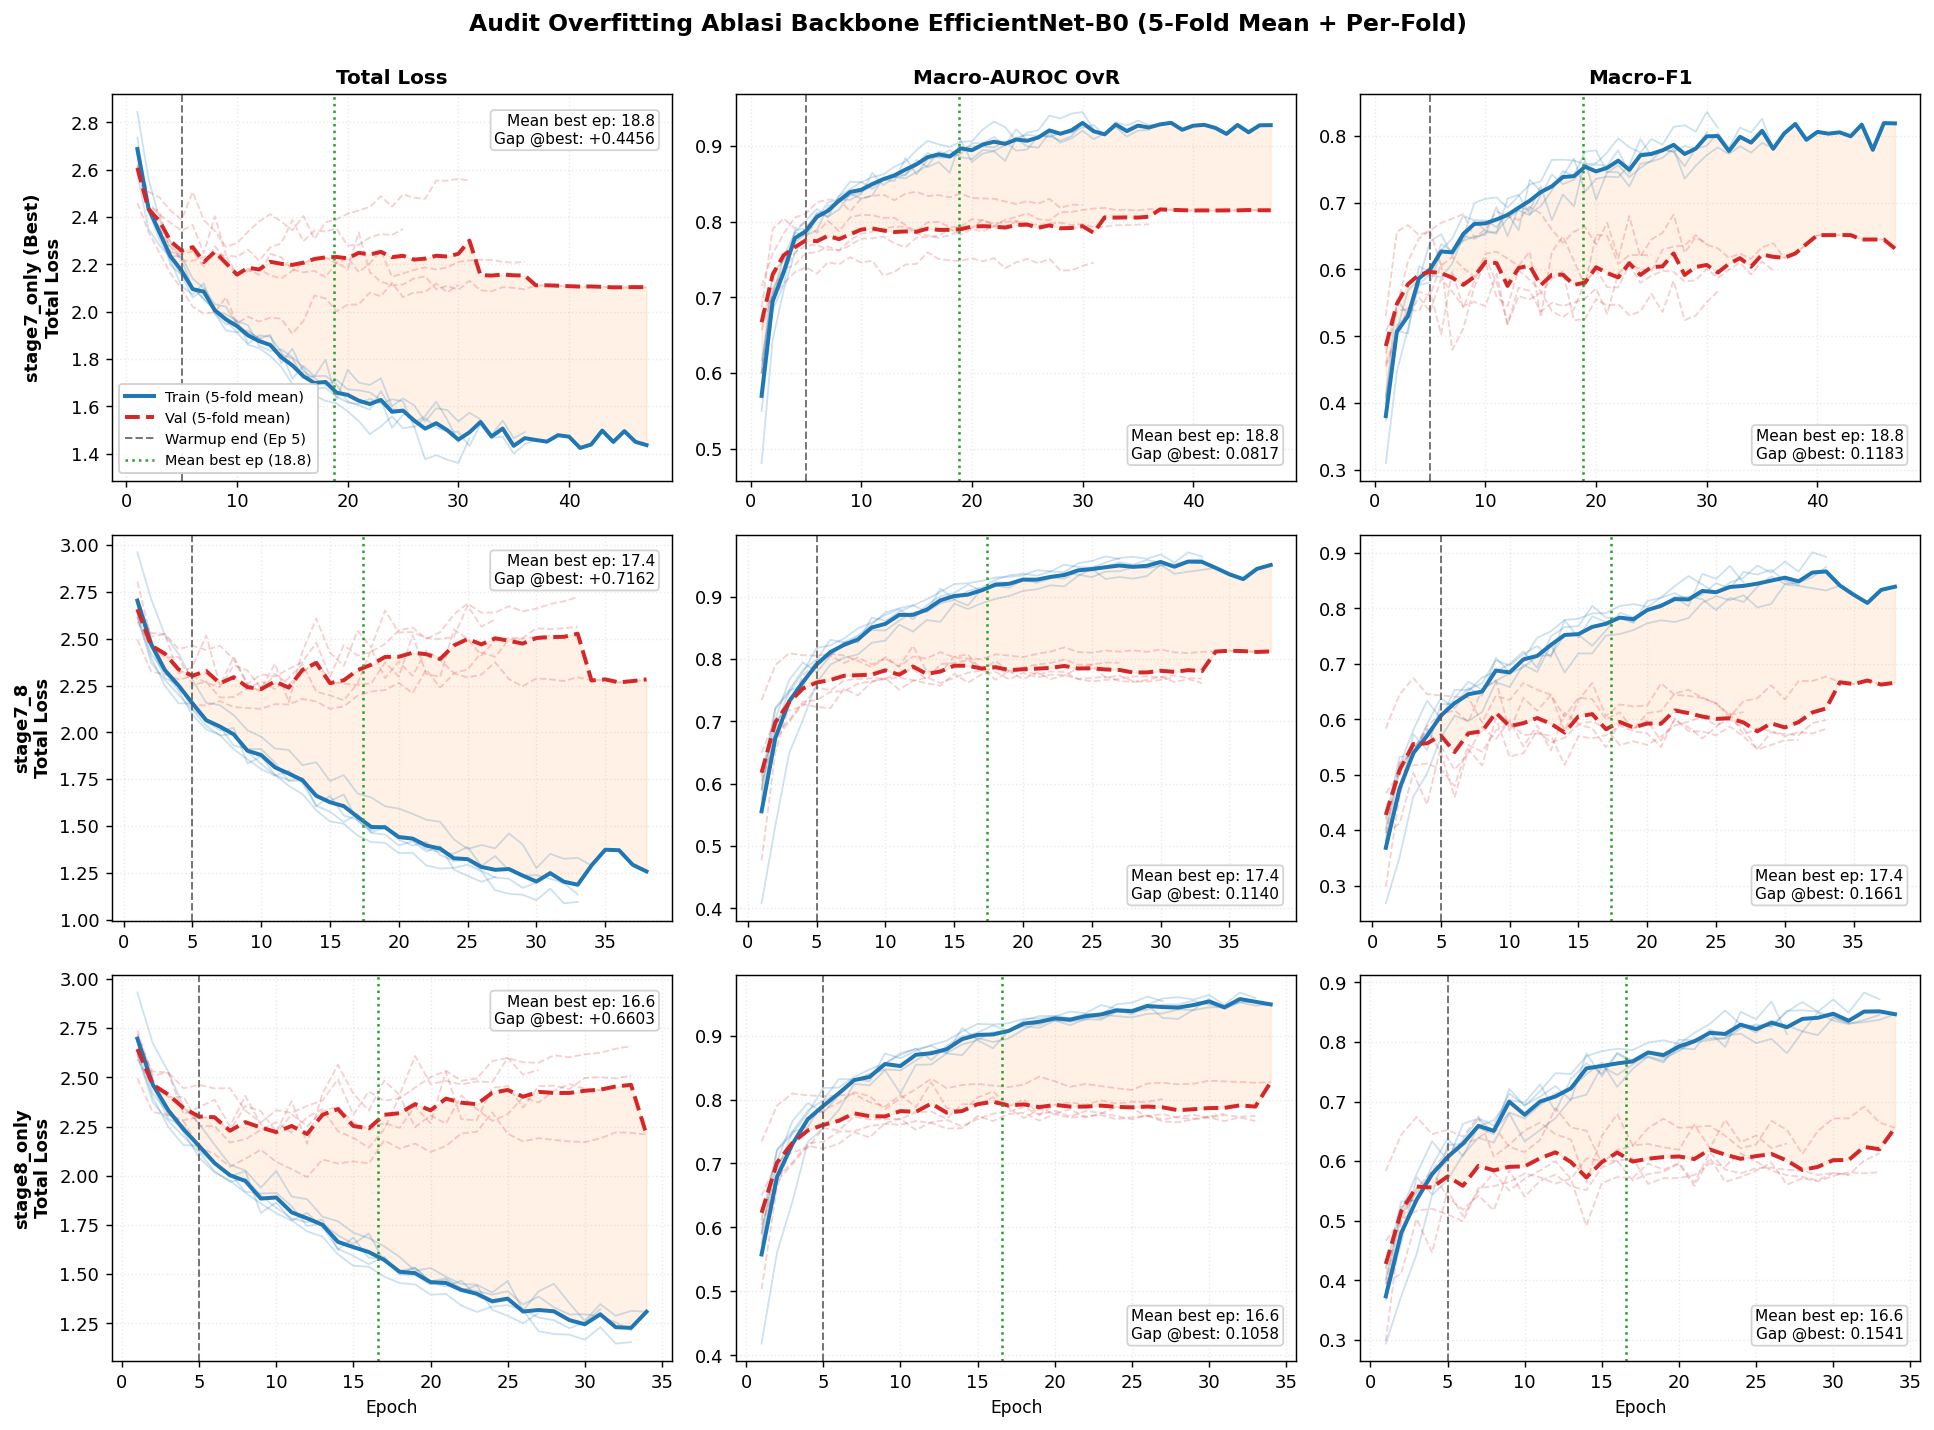

In [2]:
# ==================== BAGIAN 1: AUDIT OVERFITTING & PER-COMPONENT LOSS ====================
bb_summary_rows = []
comp_loss_rows = []
backbone_histories = {}

for b in BACKBONES:
    d = RUNS_DIR / f"02_backbone_{b}"
    if not (d / "oof_metrics_calibrated.json").exists():
        print(f"[SKIP] {d.name} belum selesai.")
        continue

    cal = json.loads((d / "oof_metrics_calibrated.json").read_text(encoding="utf-8"))
    fix = json.loads((d / "oof_metrics_fixed.json").read_text(encoding="utf-8"))

    fold_dfs = []
    best_eps, tr_l, va_l, tr_a, va_a = [], [], [], [], []
    for k in range(1, 6):
        hp = d / f"fold_{k}" / "model" / "history.csv"
        df = pd.read_csv(hp)
        fold_dfs.append(df)
        be = int(df["best_epoch"].iloc[-1])
        rb = df.loc[df["epoch"] == be].iloc[0]
        re_ = df.iloc[-1]
        r5 = df.loc[df["epoch"] == min(5, int(df["epoch"].max()))].iloc[0]

        best_eps.append(be)
        tr_l.append(float(rb["train_loss_total"]))
        va_l.append(float(rb["val_loss_total"]))
        tr_a.append(float(rb["train_primary_auroc"]))
        va_a.append(float(rb["val_primary_auroc"]))

        for st, r in (("ep5", r5), ("best", rb), ("end", re_)):
            for comp in ("diag", "comp", "hier_nll", "concept", "aux_img"):
                tr_v = float(r[f"train_loss_{comp}"])
                va_v = float(r[f"val_loss_{comp}"])
                comp_loss_rows.append({
                    "backbone_mode": b,
                    "stage": st,
                    "fold": k,
                    "component": comp,
                    "train_loss": tr_v,
                    "val_loss": va_v,
                    "gap_val_minus_train": va_v - tr_v,
                })

    backbone_histories[b] = fold_dfs
    bb_summary_rows.append({
        "backbone_mode": b,
        "oof_acc_cal": float(cal["accuracy"]),
        "oof_macro_f1_cal": float(cal["macro_f1"]),
        "oof_multiclass_auroc": float(cal["multiclass_auroc"]),
        "oof_macro_aupr": float(cal["macro_aupr"]),
        "oof_comp_recall_cal": float(cal["complication_recall"]),
        "oof_macro_f1_fixed": float(fix["macro_f1"]),
        "oof_comp_recall_fixed": float(fix["complication_recall"]),
        "mean_best_ep": float(np.mean(best_eps)),
        "mean_tr_loss_at_best": float(np.mean(tr_l)),
        "mean_va_loss_at_best": float(np.mean(va_l)),
        "mean_loss_gap_at_best": float(np.mean(np.array(va_l) - np.array(tr_l))),
        "mean_tr_auc_at_best": float(np.mean(tr_a)),
        "mean_va_auc_at_best": float(np.mean(va_a)),
        "mean_auc_gap_at_best": float(np.mean(np.array(tr_a) - np.array(va_a))),
        "va_auc_std_across_folds": float(np.std(va_a, ddof=1)),
    })

df_bb_overfit = pd.DataFrame(bb_summary_rows)
df_comp_raw = pd.DataFrame(comp_loss_rows)
df_comp_mean = (
    df_comp_raw.groupby(["backbone_mode", "stage", "component"], as_index=False)[
        ["train_loss", "val_loss", "gap_val_minus_train"]
    ]
    .mean()
)

df_bb_overfit.to_csv(OUT_DIR / "01_backbone_overfit_summary.csv", index=False)
df_comp_mean.to_csv(OUT_DIR / "02_backbone_per_component_loss.csv", index=False)

print("=== 01_backbone_overfit_summary.csv ===")
display(df_bb_overfit.round(4))
print("=== 02_backbone_per_component_loss.csv (stage=best & end) ===")
display(df_comp_mean.loc[df_comp_mean["stage"].isin(["best", "end"])].round(4))

# Plot 3x3 Kurva Overfitting
METRICS_PLOT = [
    ("Total Loss", "train_loss_total", "val_loss_total"),
    ("Macro-AUROC OvR", "train_primary_auroc", "val_primary_auroc"),
    ("Macro-F1", "train_macro_f1", "val_macro_f1"),
]
fig, axes = plt.subplots(len(backbone_histories), 3, figsize=(15, 11), sharex=False)
if len(backbone_histories) == 1:
    axes = np.expand_dims(axes, axis=0)

for r_idx, b in enumerate([x for x in BACKBONES if x in backbone_histories]):
    fold_dfs = backbone_histories[b]
    btitle = f"{b} (Best)" if b == BEST_BACKBONE else b
    mean_best_ep = float(np.mean([int(df["best_epoch"].iloc[-1]) for df in fold_dfs]))
    max_ep = max(int(df["epoch"].max()) for df in fold_dfs)
    epochs_all = np.arange(1, max_ep + 1)

    for c_idx, (mtitle, tr_col, va_col) in enumerate(METRICS_PLOT):
        ax = axes[r_idx, c_idx]
        tr_mat = np.full((len(fold_dfs), max_ep), np.nan)
        va_mat = np.full((len(fold_dfs), max_ep), np.nan)
        gaps_at_best = []

        for f_i, df in enumerate(fold_dfs):
            ep = df["epoch"].to_numpy(int)
            tr_v = df[tr_col].to_numpy(float)
            va_v = df[va_col].to_numpy(float)
            ax.plot(ep, tr_v, color="#1f77b4", alpha=0.22, lw=1.0)
            ax.plot(ep, va_v, color="#d62728", alpha=0.22, lw=1.0, ls="--")
            tr_mat[f_i, ep - 1] = tr_v
            va_mat[f_i, ep - 1] = va_v
            be = int(df["best_epoch"].iloc[-1])
            row_b = df.loc[df["epoch"] == be].iloc[0]
            gaps_at_best.append(
                float(row_b[va_col] - row_b[tr_col]) if "loss" in tr_col else float(row_b[tr_col] - row_b[va_col])
            )

        mask = np.sum(~np.isnan(tr_mat), axis=0) >= 1
        tr_mean = np.nanmean(tr_mat[:, mask], axis=0)
        va_mean = np.nanmean(va_mat[:, mask], axis=0)
        ep_m = epochs_all[mask]

        ax.plot(ep_m, tr_mean, color="#1f77b4", lw=2.2, label="Train (5-fold mean)")
        ax.plot(ep_m, va_mean, color="#d62728", lw=2.2, ls="--", label="Val (5-fold mean)")
        ax.fill_between(ep_m, tr_mean, va_mean, color="#ff7f0e", alpha=0.10)
        ax.axvline(5, color="#555555", ls="--", lw=1.1, alpha=0.8, label="Warmup end (Ep 5)" if (r_idx == 0 and c_idx == 0) else None)
        ax.axvline(mean_best_ep, color="#2ca02c", ls=":", lw=1.4, label=f"Mean best ep ({mean_best_ep:.1f})" if (r_idx == 0 and c_idx == 0) else None)

        mean_gap = float(np.mean(gaps_at_best))
        sign = "+" if ("loss" in tr_col and mean_gap >= 0) else ""
        ax.text(
            0.97, 0.95 if "loss" in tr_col else 0.05,
            f"Mean best ep: {mean_best_ep:.1f}\nGap @best: {sign}{mean_gap:.4f}",
            transform=ax.transAxes, ha="right",
            va="top" if "loss" in tr_col else "bottom", fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.85, edgecolor="#cccccc"),
        )
        if r_idx == 0:
            ax.set_title(mtitle, fontsize=11, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(f"{btitle}\n{mtitle}", fontsize=10, fontweight="bold")
        if r_idx == len(backbone_histories) - 1:
            ax.set_xlabel("Epoch", fontsize=9.5)
        ax.grid(True, alpha=0.25, linestyle=":")
        if r_idx == 0 and c_idx == 0:
            ax.legend(loc="lower left", fontsize=8, framealpha=0.9)

fig.suptitle("Audit Overfitting Ablasi Backbone EfficientNet-B0 (5-Fold Mean + Per-Fold)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_backbone_overfit_curves.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


=== 03_mil_attention_and_film_audit.csv ===
=== 04_concepts_comparison_across_backbones.csv (pivot AUROC) ===


,backbone_mode,stage,ent_norm_diag,spread_diag,ent_norm_comp,spread_comp,film_inst_delta_gamma_l2,film_bag_diag_delta_gamma_l2,film_bag_comp_delta_gamma_l2,val_concept_mean_auroc,oof_diag_p90_spread,oof_comp_p90_spread,diag_top1_is_app_rate,comp_top1_is_app_rate,mixed_random_app_rate
0,stage7_only,ep5,0.9958,0.0469,0.9999,0.0055,0.4654,0.4985,0.5559,0.5880,0.8411,0.0687,0.5161,0.6452,0.6271
1,stage7_only,best,0.7754,0.4075,0.9985,0.0306,0.8211,1.0644,1.1086,0.6422,0.8411,0.0687,0.5161,0.6452,0.6271
2,stage7_only,end,0.7412,0.4551,0.9969,0.0470,0.9406,1.2989,1.2924,0.6486,0.8411,0.0687,0.5161,0.6452,0.6271
3,stage7_8,ep5,0.9965,0.0486,1.0000,0.0054,0.4666,0.4636,0.5151,0.6013,0.6406,0.0449,0.4839,0.7419,0.6271
4,stage7_8,best,0.8602,0.3366,0.9993,0.0223,0.8036,0.9573,1.0528,0.6293,0.6406,0.0449,0.4839,0.7419,0.6271
5,stage7_8,end,0.8395,0.3651,0.9963,0.0481,0.9143,1.2211,1.2224,0.6372,0.6406,0.0449,0.4839,0.7419,0.6271
6,stage8_only,ep5,0.9967,0.0455,1.0000,0.0050,0.4695,0.4620,0.5268,0.6006,0.6404,0.0452,0.4194,0.7419,0.6271
7,stage8_only,best,0.8649,0.3277,0.9993,0.0229,0.8050,0.9392,1.0261,0.6287,0.6404,0.0452,0.4194,0.7419,0.6271
8,stage8_only,end,0.8465,0.3526,0.9966,0.0489,0.9327,1.2122,1.2081,0.6365,0.6404,0.0452,0.4194,0.7419,0.6271


backbone_mode,stage7_8,stage7_only,stage8_only
concept,,,
Appendix_Diameter,0.7006,0.7276,0.7120
Appendix_Wall_Layers,0.6633,0.6863,0.6758
Appendix_on_US,0.6754,0.6829,0.6762
Free_Fluids,0.5597,0.5921,0.5546
Pathological_Lymph_Nodes,0.6416,0.6479,0.6386
Severe_Complication_Signs,0.6738,0.6622,0.6769
Surrounding_Tissue_Reaction,0.6016,0.6288,0.5955
Target_Sign,0.5182,0.5097,0.5002


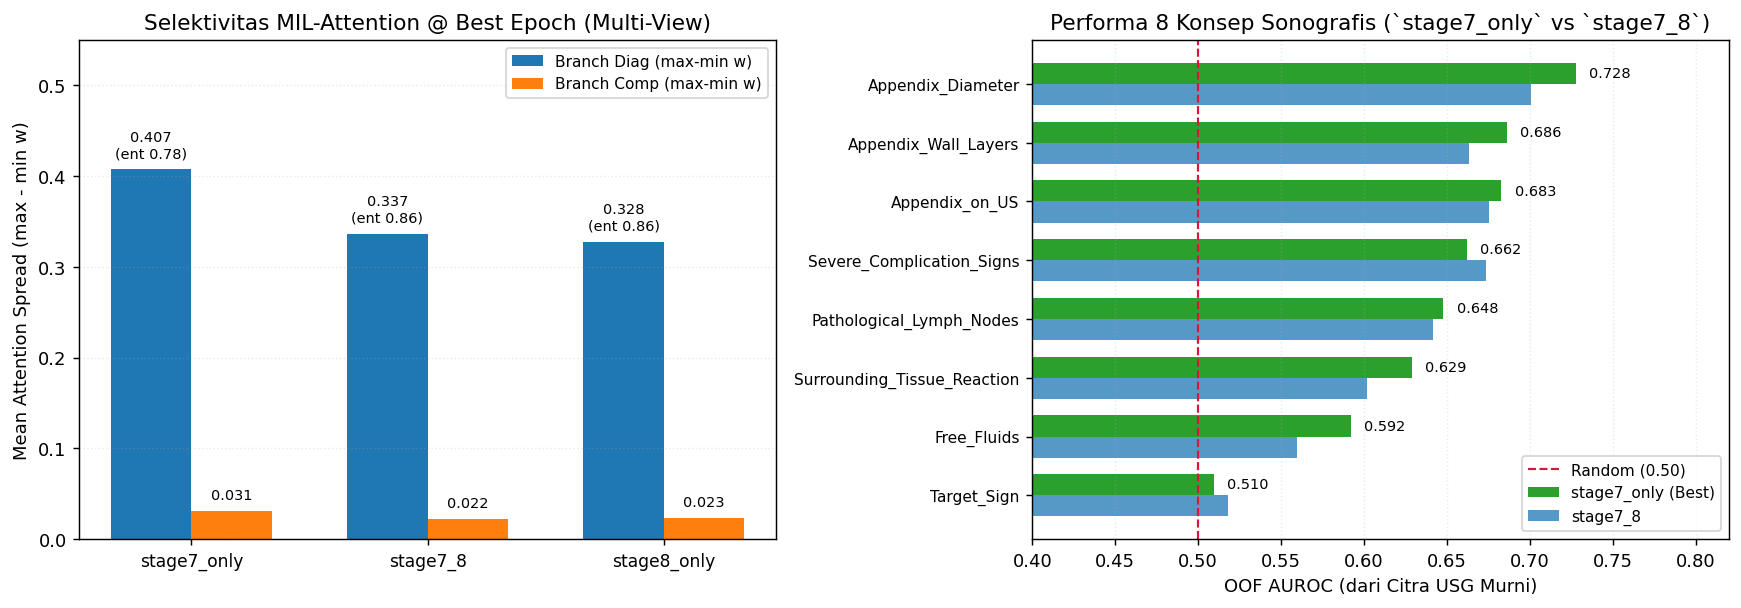

In [3]:
# ==================== BAGIAN 2: AUDIT MIL-ATTENTION, FILM, & 8 KONSEP ====================
manifest_app_map = dict(zip(manifest["image_id"], manifest["label"].apply(is_appendix_label)))
mil_film_rows = []
concept_dfs = []

for b in BACKBONES:
    d = RUNS_DIR / f"02_backbone_{b}"
    if not (d / "oof_metrics_calibrated.json").exists():
        continue

    # 1. Statistik per-epoch dari history.csv (ep5, best, end)
    ep_rows = []
    aw_list = []
    for k in range(1, 6):
        df = pd.read_csv(d / f"fold_{k}" / "model" / "history.csv")
        be = int(df["best_epoch"].iloc[-1])
        r5 = df.loc[df["epoch"] == min(5, int(df["epoch"].max()))].iloc[0]
        rb = df.loc[df["epoch"] == be].iloc[0]
        re_ = df.iloc[-1]
        for st, r in (("ep5", r5), ("best", rb), ("end", re_)):
            ep_rows.append({
                "stage": st,
                "ent_diag": float(r["val_entropy_norm_diag"]),
                "spr_diag": float(r["val_attn_spread_diag"]),
                "ent_comp": float(r["val_entropy_norm_comp"]),
                "spr_comp": float(r["val_attn_spread_comp"]),
                "inst_dg": float(r["val_inst_delta_gamma_l2"]),
                "bag_d_dg": float(r["val_bag_diag_delta_gamma_l2"]),
                "bag_c_dg": float(r["val_bag_comp_delta_gamma_l2"]),
                "concept_auc": float(r["val_concept_mean_auroc"]),
            })
        aw_k = pd.read_csv(d / f"fold_{k}" / "model" / "attention_weights.csv")
        aw_list.append(aw_k)

    ep_mean = pd.DataFrame(ep_rows).groupby("stage").mean()

    # 2. Statistik alignment bobot attention terhadap foto berlabel appendix
    aw = pd.concat(aw_list, ignore_index=True)
    aw["image_id"] = aw["image_id"].astype(str)
    aw["is_app"] = aw["image_id"].map(manifest_app_map).fillna(False)

    branch_stats = {}
    for br in ("diag", "comp"):
        sub = aw.loc[aw["branch"] == br]
        spreads, hits, rand_exp, app_w, non_w = [], [], [], [], []
        for _, g in sub.groupby("patient_id"):
            if len(g) >= 2:
                spreads.append(float(g["weight"].max() - g["weight"].min()))
                if g["is_app"].any() and (~g["is_app"]).any():
                    top_is_app = bool(g.loc[g["weight"].idxmax(), "is_app"])
                    hits.append(top_is_app)
                    rand_exp.append(float(g["is_app"].mean()))
                    app_w.append(float(g.loc[g["is_app"], "weight"].mean()))
                    non_w.append(float(g.loc[~g["is_app"], "weight"].mean()))
        branch_stats[br] = {
            "n_multiview": len(spreads),
            "oof_mean_spread": float(np.mean(spreads)) if spreads else float("nan"),
            "oof_p90_spread": float(np.percentile(spreads, 90)) if spreads else float("nan"),
            "n_mixed_app": len(hits),
            "top1_is_app": float(np.mean(hits)) if hits else float("nan"),
            "rand_is_app": float(np.mean(rand_exp)) if rand_exp else float("nan"),
            "mean_w_app": float(np.mean(app_w)) if app_w else float("nan"),
            "mean_w_non": float(np.mean(non_w)) if non_w else float("nan"),
        }

    for st in ("ep5", "best", "end"):
        r_m = ep_mean.loc[st]
        mil_film_rows.append({
            "backbone_mode": b,
            "stage": st,
            "ent_norm_diag": float(r_m["ent_diag"]),
            "spread_diag": float(r_m["spr_diag"]),
            "ent_norm_comp": float(r_m["ent_comp"]),
            "spread_comp": float(r_m["spr_comp"]),
            "film_inst_delta_gamma_l2": float(r_m["inst_dg"]),
            "film_bag_diag_delta_gamma_l2": float(r_m["bag_d_dg"]),
            "film_bag_comp_delta_gamma_l2": float(r_m["bag_c_dg"]),
            "val_concept_mean_auroc": float(r_m["concept_auc"]),
            "oof_diag_p90_spread": branch_stats["diag"]["oof_p90_spread"],
            "oof_comp_p90_spread": branch_stats["comp"]["oof_p90_spread"],
            "diag_top1_is_app_rate": branch_stats["diag"]["top1_is_app"],
            "comp_top1_is_app_rate": branch_stats["comp"]["top1_is_app"],
            "mixed_random_app_rate": branch_stats["diag"]["rand_is_app"],
        })

    cs = pd.read_csv(d / "concept_summary.csv")
    cs["backbone_mode"] = b
    concept_dfs.append(cs)

df_mil_film = pd.DataFrame(mil_film_rows)
df_concepts = pd.concat(concept_dfs, ignore_index=True)

df_mil_film.to_csv(OUT_DIR / "03_mil_attention_and_film_audit.csv", index=False)
df_concepts.to_csv(OUT_DIR / "04_concepts_comparison_across_backbones.csv", index=False)

print("=== 03_mil_attention_and_film_audit.csv ===")
display(df_mil_film.round(4))
print("=== 04_concepts_comparison_across_backbones.csv (pivot AUROC) ===")
c_piv = df_concepts.pivot(index="concept", columns="backbone_mode", values="auroc")
display(c_piv.round(4))

# Visualisasi MIL-Attention & 8 Konsep
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

sub_best = df_mil_film.loc[df_mil_film["stage"] == "best"].set_index("backbone_mode").reindex([x for x in BACKBONES if x in df_mil_film["backbone_mode"].values])
x = np.arange(len(sub_best))
w = 0.34
ax1.bar(x - w / 2, sub_best["spread_diag"], width=w, color="#1f77b4", label="Branch Diag (max-min w)")
ax1.bar(x + w / 2, sub_best["spread_comp"], width=w, color="#ff7f0e", label="Branch Comp (max-min w)")
for i, bb_name in enumerate(sub_best.index):
    ax1.text(i - w / 2, sub_best.loc[bb_name, "spread_diag"] + 0.01, f"{sub_best.loc[bb_name, 'spread_diag']:.3f}\n(ent {sub_best.loc[bb_name, 'ent_norm_diag']:.2f})", ha="center", va="bottom", fontsize=8)
    ax1.text(i + w / 2, sub_best.loc[bb_name, "spread_comp"] + 0.01, f"{sub_best.loc[bb_name, 'spread_comp']:.3f}", ha="center", va="bottom", fontsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(sub_best.index, fontsize=9.5)
ax1.set_ylim(0, max(0.55, float(sub_best["spread_diag"].max()) + 0.12))
ax1.set_ylabel("Mean Attention Spread (max - min w)")
ax1.set_title("Selektivitas MIL-Attention @ Best Epoch (Multi-View)")
ax1.grid(axis="y", alpha=0.25, ls=":")
ax1.legend(loc="upper right", fontsize=8.5)

c_order = c_piv["stage7_only"].sort_values(ascending=True).index.tolist() if "stage7_only" in c_piv.columns else list(c_piv.index)
y = np.arange(len(c_order))
h = 0.36
if "stage7_only" in c_piv.columns:
    ax2.barh(y + h / 2, c_piv.loc[c_order, "stage7_only"], height=h, color="#2ca02c", label="stage7_only (Best)")
if "stage7_8" in c_piv.columns:
    ax2.barh(y - h / 2, c_piv.loc[c_order, "stage7_8"], height=h, color="#1f77b4", alpha=0.75, label="stage7_8")
ax2.axvline(0.50, color="crimson", ls="--", lw=1.2, label="Random (0.50)")
for yi, cname in enumerate(c_order):
    if "stage7_only" in c_piv.columns:
        val = float(c_piv.loc[cname, "stage7_only"])
        ax2.text(val + 0.008, yi + h / 2, f"{val:.3f}", va="center", fontsize=8)
ax2.set_yticks(y)
ax2.set_yticklabels(c_order, fontsize=8.5)
ax2.set_xlim(0.40, 0.82)
ax2.set_xlabel("OOF AUROC (dari Citra USG Murni)")
ax2.set_title("Performa 8 Konsep Sonografis (`stage7_only` vs `stage7_8`)")
ax2.grid(axis="x", alpha=0.25, ls=":")
ax2.legend(loc="lower right", fontsize=8.5)

fig.tight_layout()
fig.savefig(OUT_DIR / "04_mil_attention_and_concepts.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


=== 05_bag_length_distribution.csv ===
AUROC HANYA dari jumlah foto (bag_len) -> binary_diag: 0.7363 | binary_sev: 0.4491
=== 06_bag_size_shortcut_correlations.csv ===
=== 07_stratified_auroc_by_bag_length.csv ===


,label,class_name,count,mean,median,std,min,max
0,0,0: No Appendicitis,196,1.9541,1.0,1.4756,1,11
1,1,1: Uncomplicated,286,3.8392,3.0,2.4066,1,15
2,2,2: Complicated,96,2.7083,2.0,2.0922,1,11


,modality,task_mode,aggregator,run_dir,oof_global_auroc,oof_macro_f1_cal,pearson_r_primary_vs_K,spearman_r_primary_vs_K,pearson_r_qcomp_vs_K,spearman_r_qcomp_vs_K
0,image_only,binary_diag,mv_mean,02_b2_image_only_binary_diag_mv_mean,0.6963,0.6507,0.1334,0.1287,NaN,NaN
1,image_only,binary_diag,mv_lstm,02_b2_image_only_binary_diag_mv_lstm,0.8025,0.7297,0.6122,0.7011,NaN,NaN
2,image_only,binary_diag,cross_attn,02_b2_image_only_binary_diag_cross_attn,0.7238,0.6342,0.2857,0.2822,NaN,NaN
3,image_only,binary_sev,mv_mean,02_b2_image_only_binary_sev_mv_mean,0.7779,0.6851,0.0090,0.0123,NaN,NaN
4,image_only,binary_sev,mv_lstm,02_b2_image_only_binary_sev_mv_lstm,0.7523,0.6097,-0.0734,-0.1301,NaN,NaN
5,image_only,binary_sev,cross_attn,02_b2_image_only_binary_sev_cross_attn,0.7820,0.6840,-0.0617,-0.0737,NaN,NaN
6,image_only,hierarchical,mv_mean,02_b2_image_only_hierarchical_mv_mean,0.6926,0.5102,0.1001,0.0953,-0.0018,0.0001
7,image_only,hierarchical,mv_lstm,02_b2_image_only_hierarchical_mv_lstm,0.7719,0.6041,0.6257,0.7117,-0.3842,-0.4995
8,image_only,hierarchical,cross_attn,02_b2_image_only_hierarchical_cross_attn,0.7005,0.4745,0.2330,0.2131,-0.0732,-0.0855
9,multimodal,binary_diag,mv_mean,02_b2_multimodal_binary_diag_mv_mean,0.8253,0.7286,0.2305,0.2101,NaN,NaN


,modality,task_mode,aggregator,oof_global_auroc,auroc_K1,n_K1,auroc_K2,n_K2,auroc_K3plus,n_K3plus
0,image_only,binary_diag,mv_mean,0.6963,0.7051,179,0.6999,123,0.7019,276
1,image_only,binary_diag,mv_lstm,0.8025,0.7108,179,0.7293,123,0.7358,276
2,image_only,binary_diag,cross_attn,0.7238,0.6903,179,0.6975,123,0.7250,276
3,image_only,binary_sev,mv_mean,0.7779,0.7748,179,0.8051,123,0.7715,276
4,image_only,binary_sev,mv_lstm,0.7523,0.7447,179,0.7871,123,0.7377,276
5,image_only,binary_sev,cross_attn,0.7820,0.7621,179,0.7571,123,0.7990,276
6,image_only,hierarchical,mv_mean,0.6926,0.6731,179,0.6639,123,0.7093,276
7,image_only,hierarchical,mv_lstm,0.7719,0.6569,179,0.6796,123,0.7301,276
8,image_only,hierarchical,cross_attn,0.7005,0.6508,179,0.6890,123,0.7002,276
9,multimodal,binary_diag,mv_mean,0.8253,0.8211,179,0.8287,123,0.8427,276


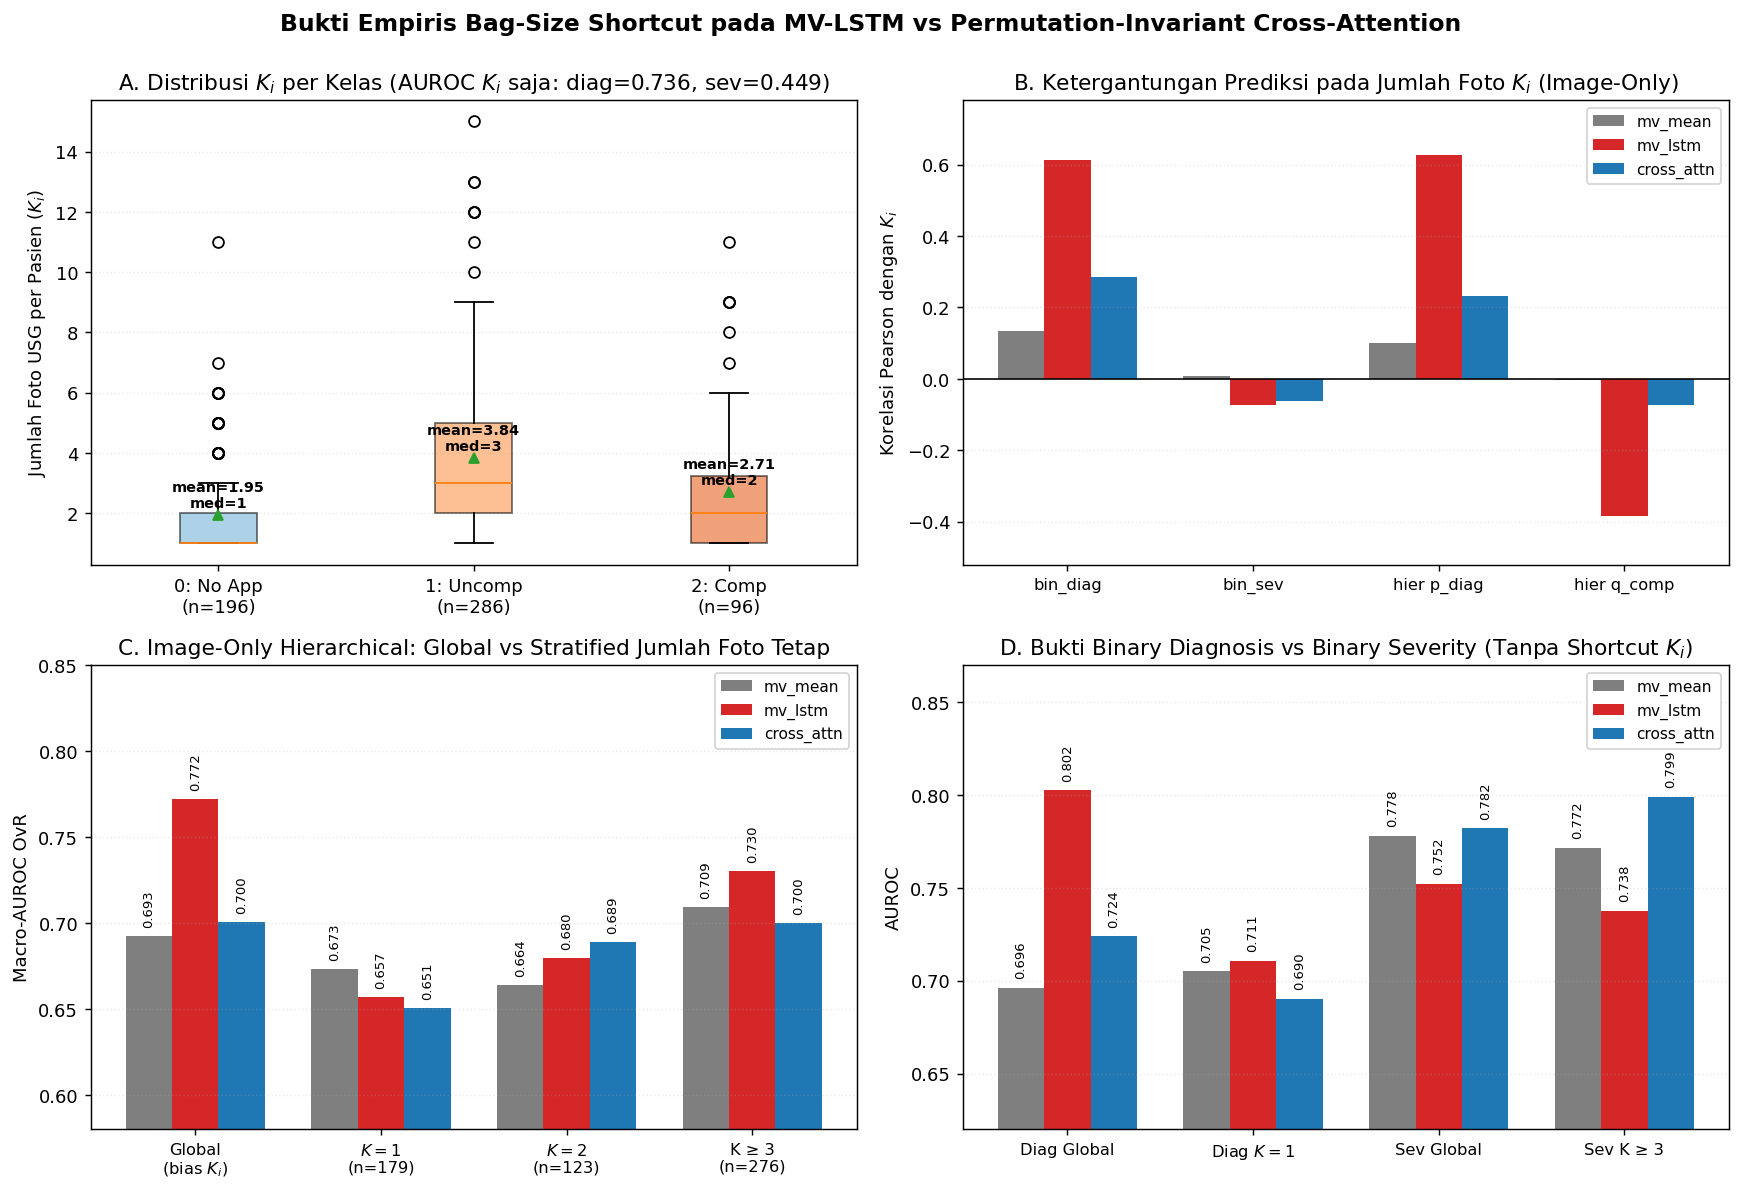

In [4]:
# ==================== BAGIAN 3: AUDIT BAG-SIZE SHORTCUT (LSTM vs CROSS-ATTENTION) ====================
cohort_bag = cohort.copy()
cohort_bag["bag_len"] = cohort_bag.index.map(lambda pid: len(bags_all[int(pid)]))

dist_df = (
    cohort_bag.groupby("label")["bag_len"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)
label_names = {0: "0: No Appendicitis", 1: "1: Uncomplicated", 2: "2: Complicated"}
dist_df["class_name"] = dist_df["label"].map(label_names)

bag_diag_auc = float(roc_auc_score((cohort_bag["label"] > 0).astype(int), cohort_bag["bag_len"]))
bag_sev_auc = float(roc_auc_score((cohort_bag["label"] == 2).astype(int), cohort_bag["bag_len"]))
dist_df["standalone_baglen_auroc_diag"] = bag_diag_auc
dist_df["standalone_baglen_auroc_sev"] = bag_sev_auc
dist_df.to_csv(OUT_DIR / "05_bag_length_distribution.csv", index=False)

print("=== 05_bag_length_distribution.csv ===")
print(f"AUROC HANYA dari jumlah foto (bag_len) -> binary_diag: {bag_diag_auc:.4f} | binary_sev: {bag_sev_auc:.4f}")
display(dist_df[["label", "class_name", "count", "mean", "median", "std", "min", "max"]].round(4))

corr_rows = []
strat_rows = []

for modality in ("image_only", "multimodal"):
    for task_mode in ("binary_diag", "binary_sev", "hierarchical"):
        for agg in ("mv_mean", "mv_lstm", "cross_attn"):
            d = resolve_b2_dir(modality, task_mode, agg)
            oof_p = d / "oof_predictions.csv"
            cal_p = d / "oof_metrics_calibrated.json"
            if not (oof_p.exists() and cal_p.exists()):
                continue

            oof = pd.read_csv(oof_p)
            cal = json.loads(cal_p.read_text(encoding="utf-8"))
            oof["K"] = oof["patient_id"].map(lambda pid: len(bags_all[int(pid)]))

            if task_mode == "hierarchical":
                global_auc = float(cal["multiclass_auroc"])
                r_diag_pearson = float(oof["p_diag"].corr(oof["K"]))
                r_diag_spear = float(spearmanr(oof["p_diag"], oof["K"]).statistic)
                r_comp_pearson = float(oof["q_comp"].corr(oof["K"]))
                r_comp_spear = float(spearmanr(oof["q_comp"], oof["K"]).statistic)
            else:
                global_auc = float(cal["auroc"])
                r_diag_pearson = float(oof["prob"].corr(oof["K"]))
                r_diag_spear = float(spearmanr(oof["prob"], oof["K"]).statistic)
                r_comp_pearson = float("nan")
                r_comp_spear = float("nan")

            corr_rows.append({
                "modality": modality,
                "task_mode": task_mode,
                "aggregator": agg,
                "run_dir": d.name,
                "oof_global_auroc": global_auc,
                "oof_macro_f1_cal": float(cal["macro_f1"]),
                "pearson_r_primary_vs_K": r_diag_pearson,
                "spearman_r_primary_vs_K": r_diag_spear,
                "pearson_r_qcomp_vs_K": r_comp_pearson,
                "spearman_r_qcomp_vs_K": r_comp_spear,
            })

            def eval_stratum(sub_df):
                if len(sub_df) < 10:
                    return float("nan")
                if task_mode == "hierarchical":
                    if len(np.unique(sub_df["label"])) < 3:
                        return float("nan")
                    return float(
                        roc_auc_score(
                            sub_df["label"],
                            sub_df[["p_0", "p_1", "p_2"]].to_numpy(),
                            labels=[0, 1, 2],
                            multi_class="ovr",
                            average="macro",
                        )
                    )
                if len(np.unique(sub_df["label"])) < 2:
                    return float("nan")
                return float(roc_auc_score(sub_df["label"], sub_df["prob"]))

            k1 = oof.loc[oof["K"] == 1]
            k2 = oof.loc[oof["K"] == 2]
            k3p = oof.loc[oof["K"] >= 3]
            strat_rows.append({
                "modality": modality,
                "task_mode": task_mode,
                "aggregator": agg,
                "oof_global_auroc": global_auc,
                "auroc_K1": eval_stratum(k1),
                "n_K1": len(k1),
                "auroc_K2": eval_stratum(k2),
                "n_K2": len(k2),
                "auroc_K3plus": eval_stratum(k3p),
                "n_K3plus": len(k3p),
            })

df_corr = pd.DataFrame(corr_rows)
df_strat = pd.DataFrame(strat_rows)
df_corr.to_csv(OUT_DIR / "06_bag_size_shortcut_correlations.csv", index=False)
df_strat.to_csv(OUT_DIR / "07_stratified_auroc_by_bag_length.csv", index=False)

print("=== 06_bag_size_shortcut_correlations.csv ===")
display(df_corr.round(4))
print("=== 07_stratified_auroc_by_bag_length.csv ===")
display(df_strat.round(4))

# Plot Bukti 2x2 Bag-Size Shortcut
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))
colors_agg = {"mv_mean": "#7f7f7f", "mv_lstm": "#d62728", "cross_attn": "#1f77b4"}

# Panel (0,0): Distribusi bag_len per kelas
ax = axes[0, 0]
bp_data = [cohort_bag.loc[cohort_bag["label"] == c, "bag_len"].to_numpy() for c in (0, 1, 2)]
bp = ax.boxplot(bp_data, tick_labels=["0: No App\n(n=196)", "1: Uncomp\n(n=286)", "2: Comp\n(n=96)"], showmeans=True, patch_artist=True)
for patch, col in zip(bp["boxes"], ["#6baed6", "#fd8d3c", "#e6550d"]):
    patch.set_facecolor(col); patch.set_alpha(0.55)
for i, arr in enumerate(bp_data, 1):
    ax.text(i, float(np.mean(arr)) + 0.15, f"mean={np.mean(arr):.2f}\nmed={np.median(arr):.0f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_ylabel("Jumlah Foto USG per Pasien ($K_i$)")
ax.set_title(f"A. Distribusi $K_i$ per Kelas (AUROC $K_i$ saja: diag={bag_diag_auc:.3f}, sev={bag_sev_auc:.3f})")
ax.grid(axis="y", alpha=0.25, ls=":")

# Panel (0,1): Korelasi prediksi dengan K_i (Image-Only)
ax = axes[0, 1]
sub_c = df_corr.loc[df_corr["modality"] == "image_only"].copy()
keys_c = [("binary_diag", "pearson_r_primary_vs_K", "bin_diag"),
          ("binary_sev", "pearson_r_primary_vs_K", "bin_sev"),
          ("hierarchical", "pearson_r_primary_vs_K", "hier p_diag"),
          ("hierarchical", "pearson_r_qcomp_vs_K", "hier q_comp")]
x = np.arange(len(keys_c))
w = 0.25
for j, agg in enumerate(("mv_mean", "mv_lstm", "cross_attn")):
    vals = []
    for tm, col, _ in keys_c:
        row = sub_c.loc[(sub_c["task_mode"] == tm) & (sub_c["aggregator"] == agg)]
        vals.append(float(row[col].iloc[0]) if len(row) else 0.0)
    ax.bar(x + (j - 1) * w, vals, width=w, color=colors_agg[agg], label=agg)
ax.axhline(0, color="black", lw=0.9)
ax.set_xticks(x)
ax.set_xticklabels([k[2] for k in keys_c], fontsize=9)
ax.set_ylim(-0.52, 0.78)
ax.set_ylabel("Korelasi Pearson dengan $K_i$")
ax.set_title("B. Ketergantungan Prediksi pada Jumlah Foto $K_i$ (Image-Only)")
ax.grid(axis="y", alpha=0.25, ls=":")
ax.legend(loc="upper right", fontsize=8.5)

# Panel (1,0): Image-Only Hierarchical: Global vs Stratified K=1, K=2, K>=3
ax = axes[1, 0]
sub_h = df_strat.loc[(df_strat["modality"] == "image_only") & (df_strat["task_mode"] == "hierarchical")].set_index("aggregator")
strata_cols = [("oof_global_auroc", "Global\n(bias $K_i$)"), ("auroc_K1", "$K=1$\n(n=179)"), ("auroc_K2", "$K=2$\n(n=123)"), ("auroc_K3plus", "K ≥ 3\n(n=276)")]
x = np.arange(len(strata_cols))
for j, agg in enumerate(("mv_mean", "mv_lstm", "cross_attn")):
    if agg not in sub_h.index:
        continue
    vals = [float(sub_h.loc[agg, c]) for c, _ in strata_cols]
    bars = ax.bar(x + (j - 1) * w, vals, width=w, color=colors_agg[agg], label=agg)
    for b_bar, v in zip(bars, vals):
        ax.text(b_bar.get_x() + b_bar.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=7.3, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels([lbl for _, lbl in strata_cols], fontsize=9)
ax.set_ylim(0.58, 0.85)
ax.set_ylabel("Macro-AUROC OvR")
ax.set_title("C. Image-Only Hierarchical: Global vs Stratified Jumlah Foto Tetap")
ax.grid(axis="y", alpha=0.25, ls=":")
ax.legend(loc="upper right", fontsize=8.5)

# Panel (1,1): Binary Diagnosis vs Binary Severity (efek hilangnya shortcut K_i)
ax = axes[1, 1]
sub_bin = df_strat.loc[(df_strat["modality"] == "image_only") & (df_strat["task_mode"].isin(["binary_diag", "binary_sev"]))].copy()
cats = [("binary_diag", "oof_global_auroc", "Diag Global"),
        ("binary_diag", "auroc_K1", "Diag $K=1$"),
        ("binary_sev", "oof_global_auroc", "Sev Global"),
        ("binary_sev", "auroc_K3plus", "Sev K ≥ 3")]
x = np.arange(len(cats))
for j, agg in enumerate(("mv_mean", "mv_lstm", "cross_attn")):
    vals = []
    for tm, col, _ in cats:
        r = sub_bin.loc[(sub_bin["task_mode"] == tm) & (sub_bin["aggregator"] == agg)]
        vals.append(float(r[col].iloc[0]) if len(r) else float("nan"))
    bars = ax.bar(x + (j - 1) * w, vals, width=w, color=colors_agg[agg], label=agg)
    for b_bar, v in zip(bars, vals):
        if np.isfinite(v):
            ax.text(b_bar.get_x() + b_bar.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=7.3, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels([lbl for _, _, lbl in cats], fontsize=9)
ax.set_ylim(0.62, 0.87)
ax.set_ylabel("AUROC")
ax.set_title("D. Bukti Binary Diagnosis vs Binary Severity (Tanpa Shortcut $K_i$)")
ax.grid(axis="y", alpha=0.25, ls=":")
ax.legend(loc="upper right", fontsize=8.5)

fig.suptitle("Bukti Empiris Bag-Size Shortcut pada MV-LSTM vs Permutation-Invariant Cross-Attention", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
fig.savefig(OUT_DIR / "07_bag_size_shortcut_proof.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


In [5]:
# ==================== BAGIAN 4: RINGKASAN LAPORAN SIAP KUTIP ====================
lines = []
lines.append("========================================================================")
lines.append("AUDIT DIAGNOSTIK PROPOSED MODEL 3 — OVERFITTING, MIL, FILM, KONSEP & SHORTCUT")
lines.append("========================================================================")
lines.append("")
lines.append("1. PERBANDINGAN BACKBONE & OVERFITTING (02 Ablasi Backbone)")
for _, r in df_bb_overfit.iterrows():
    lines.append(
        f"  - {r['backbone_mode']:11s}: Acc={r['oof_acc_cal']:.4f} | MacroF1={r['oof_macro_f1_cal']:.4f} | "
        f"AUROC={r['oof_multiclass_auroc']:.4f} | AUPR={r['oof_macro_aupr']:.4f} | CompRec={r['oof_comp_recall_cal']:.4f} | "
        f"BestEp={r['mean_best_ep']:.1f} | LossGap@Best={r['mean_loss_gap_at_best']:+.4f} | AUCGap@Best={r['mean_auc_gap_at_best']:+.4f}"
    )

lines.append("")
lines.append("2. KERJA MIL-ATTENTION, FILM, & 8 KONSEP (@Best Epoch)")
for _, r in df_mil_film.loc[df_mil_film["stage"] == "best"].iterrows():
    lines.append(
        f"  - {r['backbone_mode']:11s}: diag_ent={r['ent_norm_diag']:.4f}, diag_spread={r['spread_diag']:.4f} (p90={r['oof_diag_p90_spread']:.4f}) | "
        f"comp_ent={r['ent_norm_comp']:.4f}, comp_spread={r['spread_comp']:.4f} | "
        f"FiLM inst_dg={r['film_inst_delta_gamma_l2']:.3f}, bag_d_dg={r['film_bag_diag_delta_gamma_l2']:.3f}, bag_c_dg={r['film_bag_comp_delta_gamma_l2']:.3f} | "
        f"Concept_AUC={r['val_concept_mean_auroc']:.4f}"
    )

lines.append("")
lines.append("3. DISTRIBUSI JUMLAH FOTO USG (K_i) & SHORTCUT STANDALONE")
for _, r in dist_df.iterrows():
    lines.append(f"  - {r['class_name']:20s}: n={int(r['count']):3d}, mean={r['mean']:.2f}, median={r['median']:.1f}, std={r['std']:.2f}")
lines.append(f"  - AUROC hanya dari jumlah foto K_i -> binary_diag={bag_diag_auc:.4f} | binary_sev={bag_sev_auc:.4f}")

lines.append("")
lines.append("4. KORELASI PREDIKSI VS K_i & AUROC TERSTRATIFIKASI (K=1, K=2, K>=3)")
merged_b2 = df_corr.merge(
    df_strat[["modality", "task_mode", "aggregator", "auroc_K1", "auroc_K2", "auroc_K3plus"]],
    on=["modality", "task_mode", "aggregator"],
    how="left",
)
for _, r in merged_b2.iterrows():
    q_str = f", r(q_comp,K)={r['pearson_r_qcomp_vs_K']:+.4f}" if pd.notna(r["pearson_r_qcomp_vs_K"]) else ""
    lines.append(
        f"  - {r['modality']:10s} | {r['task_mode']:12s} | {r['aggregator']:10s} -> "
        f"Global={r['oof_global_auroc']:.4f} | K=1:{r['auroc_K1']:.4f} | K=2:{r['auroc_K2']:.4f} | K>=3:{r['auroc_K3plus']:.4f} | "
        f"r(pred,K)={r['pearson_r_primary_vs_K']:+.4f}{q_str}"
    )

report_text = "\n".join(lines)
report_path = OUT_DIR / "05_diagnostic_audit_report.txt"
report_path.write_text(report_text, encoding="utf-8")
print(report_text)
print(f"\nSemua tabel CSV, PNG, dan laporan tersimpan di: {OUT_DIR}")


AUDIT DIAGNOSTIK PROPOSED MODEL 3 — OVERFITTING, MIL, FILM, KONSEP & SHORTCUT

1. PERBANDINGAN BACKBONE & OVERFITTING (02 Ablasi Backbone)
  - stage7_only: Acc=0.6384 | MacroF1=0.6291 | AUROC=0.8009 | AUPR=0.6410 | CompRec=0.6042 | BestEp=18.8 | LossGap@Best=+0.4456 | AUCGap@Best=+0.0817
  - stage7_8   : Acc=0.6401 | MacroF1=0.6222 | AUROC=0.7925 | AUPR=0.6216 | CompRec=0.5208 | BestEp=17.4 | LossGap@Best=+0.7162 | AUCGap@Best=+0.1140
  - stage8_only: Acc=0.6298 | MacroF1=0.6150 | AUROC=0.7992 | AUPR=0.6303 | CompRec=0.5521 | BestEp=16.6 | LossGap@Best=+0.6603 | AUCGap@Best=+0.1058

2. KERJA MIL-ATTENTION, FILM, & 8 KONSEP (@Best Epoch)
  - stage7_only: diag_ent=0.7754, diag_spread=0.4075 (p90=0.8411) | comp_ent=0.9985, comp_spread=0.0306 | FiLM inst_dg=0.821, bag_d_dg=1.064, bag_c_dg=1.109 | Concept_AUC=0.6422
  - stage7_8   : diag_ent=0.8602, diag_spread=0.3366 (p90=0.6406) | comp_ent=0.9993, comp_spread=0.0223 | FiLM inst_dg=0.804, bag_d_dg=0.957, bag_c_dg=1.053 | Concept_AUC=0.6293